## Basic Idea

The idea is to include a feature in ponds with which the user can check how well its detection tool worked. The assumption is that the detection tool takes the PONDS time series and provides a nc-file containing information about shift clusters it found in the data. The new function shall take this file/dataset and compare it to the shift cluster of the PONDS object. It comes up with a score which quantifies the performance of the detection-pipeline.

Hence, the deduced issue to solve is on how to compare clusters masks with each other. Potential detection errors are:

- detector interprets one event cluster as two or more distinct clusters
- detector does not find a cluster at all
- detector finds the cluster and misses grid cells which are part of the original cluster
- detector finds the cluster and adds grid cells which are not part of the original cluster


## ToDo:

- Literature Search: find metrics for comparing cluster masks
- single out best option(s)
- implement a class function that applies the metric(s)
- write testing
- write tutorial

# Overall Perfromance

- check how well the detection of shift cells worked
- measured by comparing the total number of ground-truth (GT) shift cells with the detected (D) shift cells
- Hence, all input and output cluster masks are aggregated

## Literature Search: What is out there?

### Jaccard Index (a.k.a IoU Index)

[Wikipedia:](https://en.wikipedia.org/wiki/Jaccard_index) <br>
The Jaccard index measures similarity between finite non-empty sample sets and is defined as the size of the intersection divided by the size of the union of the sample sets:

$${\displaystyle J(A,B)={\frac {|A\cap B|}{|A\cup B|}}={\frac {|A\cap B|}{|A|+|B|-|A\cap B|}}.} $$

Note that by design, ${\displaystyle 0\leq J(A,B)\leq 1.}$ If the sets ${\displaystyle A}$ and ${\displaystyle B}$ have no elements in common, their intersection is empty, so ${\displaystyle |A\cap B|=0}$ and therefore ${\displaystyle J(A,B)=0.}$ The other extreme is that the two sets are equal. In that case ${\displaystyle A\cap B=A\cup B=A=B,}$ so then ${\displaystyle J(A,B)=1.}$


### Rand Index

[Wikipedia:](https://en.wikipedia.org/wiki/Rand_index) <br>
Given a set of ${\displaystyle n}$ elements ${\displaystyle S=\{o_{1},\ldots ,o_{n}\}}$ and two partitions of ${\displaystyle S}$ to compare, ${\displaystyle X=\{X_{1},\ldots ,X_{r}\}}$, a partition of S into r subsets, and ${\displaystyle Y=\{Y_{1},\ldots ,Y_{s}\}}$, a partition of S into s subsets, define the following:

- ${\displaystyle a}$, the number of pairs of elements in ${\displaystyle S}$ that are in the same subset in ${\displaystyle X}$ and in the same subset in ${\displaystyle Y}$
- ${\displaystyle b}$, the number of pairs of elements in ${\displaystyle S}$ that are in different subsets in ${\displaystyle X}$ and in different subsets in ${\displaystyle Y}$
- ${\displaystyle c}$, the number of pairs of elements in ${\displaystyle S}$ that are in the same subset in ${\displaystyle X}$ and in different subsets in ${\displaystyle Y}$
- ${\displaystyle d}$, the number of pairs of elements in ${\displaystyle S}$ that are in different subsets in ${\displaystyle X}$ and in the same subset in ${\displaystyle Y}$

The Rand index, ${\displaystyle R}$, is:

$${\displaystyle R={\frac {a+b}{a+b+c+d}}={\frac {a+b}{n \choose 2}} \enspace \enspace \left[= {\frac {TP + TN}{TP + TN + FP + FN}} \right]} $$

Intuitively, ${\displaystyle a+b}$ can be considered as the number of agreements between ${\displaystyle X}$ and ${\displaystyle Y}$ and ${\displaystyle c+d}$ as the number of disagreements between ${\displaystyle X}$ and ${\displaystyle Y}$.


### Dice-Sørensen coefficient / Dice score

[Wikipedia:](https://en.wikipedia.org/wiki/Dice-S%C3%B8rensen_coefficient) <br>
Sørensen's original formula was intended to be applied to discrete data. Given two sets, $X$ and $Y$, it is defined as

$${\displaystyle DSC={\frac {2|X\cap Y|}{|X|+|Y|}}}$$

where $|X|$ and $|Y|$ are the cardinalities of the two sets (i.e. the number of elements in each set). The Sørensen index equals twice the number of elements common to both sets divided by the sum of the number of elements in each set. Equivalently, the index is the size of the intersection as a fraction of the average size of the two sets. 

### Relation between Jaccard Index and Dice Score

Sources: <br>
[StackExchange](https://stats.stackexchange.com/questions/273537/f1-dice-score-vs-iou) and [Wikipedia](https://en.wikipedia.org/wiki/Dice-S%C3%B8rensen_coefficient)

Turns out that the Jaccard index and the Dice score are very similar! For boolean data, they can be rewritten as:

$$ J = \frac{TP}{TP+FP+FN} $$

and

$$ DSC = \frac{2TP}{2TP+FP+FN}$$

Hence, they have the relation:

$$ {\displaystyle J=DSC/(2-DSC)} $$

"It is tempting then to conclude that the two metrics are functionally equivalent so the choice between them is arbitrary, but not so fast! The problem comes when taking the average score over a set of inferences. Then the difference emerges when quantifying how much worse [detector] B is than A for any given case.

In general, the [Jaccard index] tends to penalize single instances of bad classification more than the [Dice score] quantitatively even when they can both agree that this one instance is bad. Similarly to how L2 can penalize the largest mistakes more than L1, the [Jaccard index] tends to have a "squaring" effect on the errors relative to the [Dice score]. So the [Dice score] tends to measure something closer to average performance, while the [Jaccard index] measures something closer to the worst case performance.

Suppose for example that the vast majority of the inferences are moderately better with [detector] A than B, but some of them of them are significantly worse using [detector] A. It may be the case then that the [Dice score] favors [detector] A while the [Jaccard index] favors [detector] B." - [[StackExchange, 2017]](https://stats.stackexchange.com/questions/273537/f1-dice-score-vs-iou)

### ToDo:

- Check if this last statement is true! If so, prioritise Dice score!
- also implement Jaccard index using relation of the two

In [31]:
import numpy as np

def D_score(
        mask1,
        mask2
    ):
    """
    """
    
    TP = np.sum(np.logical_and(mask1, mask2))
    FP = np.sum(np.logical_and(np.logical_not(mask1), mask2))
    FN = np.sum(np.logical_and(mask1, np.logical_not(mask2)))

    score = 2*TP / (2*TP + FP + FN)
    return score

def J_score(
        mask1,
        mask2
    ):
    """
    """
    score = D_score(mask1, mask2)
    score = score / (2 - score)

    return score

def R_score(
        mask1,
        mask2
    ):
    """
    """
    TP = np.sum(np.logical_and(mask1, mask2))
    TN = np.sum(np.logical_and(np.logical_not(mask1), np.logical_not(mask2)))
    FP = np.sum(np.logical_and(np.logical_not(mask1), mask2))
    FN = np.sum(np.logical_and(mask1, np.logical_not(mask2)))

    score = (TP + TN) / (TP + TN + FP + FN)
    return score


mask1 = np.array(
    [[1, 1, 0],
     [0, 1, 0],
     [0, 0, 1]],
    dtype=np.bool_
    )
mask2 = np.array(
    [[1, 1, 0],
     [0, 1, 0],
     [0, 1, 0]],
    dtype=np.bool_
    )
mask3 = np.array(
    [[1, 1, 0],
     [0, 1, 0],
     [0, 0, 0]],
    dtype=np.bool_
    )

print("Comparing mask1 and mask2:")
D = D_score(mask1, mask2)
print("D-score:", D)
J = J_score(mask1, mask2)
print("J-score:", J)
R = R_score(mask1, mask2)
print("R-score:", R)

print("\nComparing mask1 and mask3:")
D = D_score(mask1, mask3)
print("D-score:", D)
J = J_score(mask1, mask3)
print("J-score:", J)
R = R_score(mask1, mask3)
print("R-score:", R)

Comparing mask1 and mask2:
D-score: 0.75
J-score: 0.6
R-score: 0.7777777777777778

Comparing mask1 and mask3:
D-score: 0.8571428571428571
J-score: 0.75
R-score: 0.8888888888888888


# Unification and Fragmentation

When comparing TOAD and PONDS so far, it often happened that TOAD fragments a cluster into severall sub-cluster. Hence, I want a metric which focuses on quantifiying this performance. For starters, this is oriented on the TOAD clustering data format. This format is 3 dimensional, containing 2 spacial and 1 temporal dimension. Each point in this data cube contains a scalar integer value, specifying the belonging to a given cluster index. The value `-1` is special and indicates that this point in space-time does not belong to any cluster.

On the other hand, PONDS is treating distinct shift cluster as distinct xarray objects. Hence, a single point in space-time is allowed to be part of several cluster events. So maybe it might be better to split the TOAD clustering data into dinstinct xarray DataArrays.

## Fragmentation

### Objectives for Fragmentation

1. Optimum is one large cluster which (mostly) identifies with the ground truth (GT).
2. The larger this central cluster, the better.
3. Each subcluster gets penalized.
4. Larger subclusters are getting penalized more.

ChatGPT recommends:

Define the per-cluster Fragmentation Index (FI) in [0,1] as

$$ FI(GT) = (1−r)  +  r \cdot (1−\frac{\sum_{j=1}^{k}s_j^{2}}{O^{2}}) $$

where $r=\frac{O}{A}$ is the coverage ratio (fraction of GT covered by any detection), with $O = \sum_{j=1}^{k} s_j$ and $A = |GT|$.

To understand this formula:

- $(1 - r) = (1 - \frac{O}{A})$ penalizes the coverage. The more cluster cells are missed, the larger this term.
- $(1 - \frac{\sum_{j=1}^{k} s_{j}^{2}}{O^{2}}) = (1 - \sum_i\frac{s_i^2}{O^2}) = (1 - \sum_i p_i^2)$ is the [Gini-Simpson index](https://en.wikipedia.org/wiki/Diversity_index#Gini%E2%80%93Simpson_index) (GS), which measure the probability that two randomly chosen entities represent different types, in our case different cluster.

So the agenda for computing the **Fragmentation Score** is:
- find overlap-matrix between GT-cluster and D-cluster
- compute fragmentation score per GT-cluster
- average over all GT-cluster and present single, final score

---

**Idea:** Strip it down to just the GSI? <br>
**Answer:** No, because if we get rid of r entirely the GSI is independant on the actual sizes of $s_i$ and only depends on the relative values.So for example, if I only detect two subcluster which are of equal size and each only a tiny fraction of the GT cluster, the GSI is identical to the case were I detect two subcluster splitting the whole GT cluster in half.

In [132]:
def overlap_score(GT_masks, D_masks, temporal_uncertainty=0):
    """
    """
    score = np.zeros((len(GT_masks), len(D_masks)))
    for i in range(len(GT_masks)):
        for j in range(len(D_masks)):
            # find the best temporal alignment within the uncertainty range
            vals = np.zeros((2 * temporal_uncertainty + 1,))    # make space to choose best match from
            for t_os in range(-temporal_uncertainty, temporal_uncertainty + 1):
                shifted_mask = np.roll(D_masks[j], shift=t_os, axis=0)      # shift in time axis
                vals[t_os + temporal_uncertainty] = np.sum(np.logical_and(GT_masks[i], shifted_mask))   # find number of matching voxels for shifted mask

            score[i, j] = np.max(vals)  # choose best match
    return score

def F_score(GT_mag, D_mags):

    #if GT_mag < np.sum(D_mags):
    #    raise ValueError("GT magnitude must be larger than or equal to the sum of detected magnitudes.")

    O = np.sum(D_mags)
    A = GT_mag
    r = O/float(A)

    if O <= 0:
        return 1.0
    else:
        F = 1 - r
        F += r * (1 - np.sum(D_mags**2) / O**2)
        return F

In [133]:
import numpy as np

# very simple example of fragmentation
c1 = np.array(          # ground truth
    [[0, 1, 1],
     [0, 1, 1],
     [0, 0, 0]],
     dtype=np.bool_)
c2 = np.array(          # ground truth
    [[0, 0, 0],
     [0, 0, 0],
     [1, 1, 0]],
     dtype=np.bool_)

s1 = np.array(          # detected fragment 1
    [[0, 1, 0],
     [0, 1, 1],
     [0, 0, 0]],
     dtype=np.bool_)
s2 = np.array(          # detected fragment 2
    [[0, 0, 1],
     [0, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
s3 = np.array(          # detected fragment 2
    [[0, 0, 0],
     [0, 0, 0],
     [1, 0, 0]],
     dtype=np.bool_)
s4 = np.array(          # detected fragment 2
    [[0, 0, 0],
     [0, 0, 0],
     [0, 1, 0]],
     dtype=np.bool_)

GT_masks = {0: c1, 1: c2}
D_masks = {0: s1, 1: s2, 2: s3, 3: s4}

i = 1
OS = overlap_score(GT_masks, D_masks)
print("Overlap score matrix:")
print(OS)
FS = F_score(np.sum(GT_masks[i]), OS[i])
print(f"F-score of GT-cluster-{i}:", FS)

Overlap score matrix:
[[3. 1. 0. 0.]
 [0. 0. 1. 1.]]
F-score of GT-cluster-1: 0.5


In [127]:
GT = 13
score = np.full(GT, 1)#np.array([1,1,1,1,1,1])
score[0] = int(0.5 * GT)
score[-score[0]+1:] = 0
print(score)

print(F_score(GT, score))

[6 1 1 1 1 1 1 1 0 0 0 0 0]
0.7455621301775148


In [128]:
score = np.array([5,4,3,1,1])
GT = np.sum(score)
print(f"{GT=}")
print(f"{score=}")

print(f"{F_score(GT, score)=}")

GT=np.int64(14)
score=array([5, 4, 3, 1, 1])
F_score(GT, score)=np.float64(0.7346938775510203)


### Fragmentation on PONDS and TOAD

## Unification

### Agenda for Unification

We measure how much unification happened for a given, detected cluster.

- find overlap-matrix between GT-cluster and D-cluster
- compute fragmentation score per D-cluster
- average over all D-cluster and present single, final score

In [129]:
import numpy as np

# very simple example of fragmentation
c1 = np.array(          # ground truth
    [[0, 1, 1],
     [0, 1, 1],
     [0, 0, 0]],
     dtype=np.bool_)
c2 = np.array(          # ground truth
    [[1, 0, 0],
     [1, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c3 = np.array(          # ground truth
    [[0, 0, 0],
     [0, 0, 0],
     [1, 1, 0]],
     dtype=np.bool_)

s1 = np.array(          # detected fragment 1
    [[1, 1, 1],
     [1, 1, 1],
     [0, 1, 0]],
     dtype=np.bool_)
s2 = np.array(          # detected fragment 2
    [[0, 0, 0],
     [0, 0, 0],
     [1, 0, 0]],
     dtype=np.bool_)
GT_masks = {0: c1, 1: c2, 2: c3}
D_masks = {0: s1, 1: s2}

i = 0
OS = overlap_score(GT_masks, D_masks)
print("Overlap score matrix:")
print(OS)
US = F_score(np.sum(D_masks[i]), OS[:,i])
print(f"U-score of D-cluster-{i}:", US)

Overlap score matrix:
[[4. 0.]
 [2. 0.]
 [1. 1.]]
U-score of D-cluster-0: 0.5714285714285714


### Alternative for Unification

We choose  similar formula as for the fragmentation. The main difference is the weighting:

$$ U (g_i) = \frac{k_{i*}}{|g_i|} (1- \frac{k_{i*}^2}{A_{i*}^2})  $$

with $k_{i*}$ being the number of elemts that are in the ground truth cluster $g_i$ **and** in the best-matching detection cluster $d^*$. $A_{i*}$ is the overal size of $d^*$ (so also including FP cells).

The advantage of this approach is, that we receive a score for every ground-truth cluster and not for every detection cluster.

In [135]:
def U_score(D_mag, GT_mag, overlap):

    res = overlap / GT_mag
    res *= (1 - (overlap/D_mag)**2)

    return res

def best_match(overlap_score, ix):

    res = np.argmax(overlap_score[ix, :])
    return res


In [148]:
import numpy as np

# very simple example of fragmentation
c1 = np.array(          # ground truth
    [[0, 1, 1],
     [0, 1, 1],
     [0, 0, 0]],
     dtype=np.bool_)
c2 = np.array(          # ground truth
    [[1, 0, 0],
     [1, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c3 = np.array(          # ground truth
    [[0, 0, 0],
     [0, 0, 0],
     [1, 1, 0]],
     dtype=np.bool_)

s1 = np.array(          # detected fragment 1
    [[1, 1, 1],
     [1, 1, 0],
     [0, 0, 0]],
     dtype=np.bool_)
s2 = np.array(          # detected fragment 2
    [[0, 0, 0],
     [0, 0, 1],
     [1, 1, 0]],
     dtype=np.bool_)
GT_masks = {0: c1, 1: c2, 2: c3}
D_masks = {0: s1, 1: s2}

i = 2
OS = overlap_score(GT_masks, D_masks)
print("Overlap score matrix:")
print(OS)
BM = best_match(OS, i)
print(f"Best match for GT-cluster-{i} is D-cluster-{BM}")

US = U_score(np.sum(D_masks[BM]), np.sum(GT_masks[i]), OS[i,BM])
print(f"U-score of D-cluster-{i}:", US)

Overlap score matrix:
[[3. 1.]
 [2. 0.]
 [0. 2.]]
Best match for GT-cluster-2 is D-cluster-1
U-score of D-cluster-2: 0.5555555555555556


## Element-centric Clustering Comparison

According to [[Gates et al., 2019]](https://www.nature.com/articles/s41598-019-44892-y), the _element-centric clustering comparison_ is superior to most other cluster comparison measures considering the categories

1. randomized membership
2. skewed cluster size
3. number of clusters
4. cluster matching

See Figure 2d for a comparison with other measures within these categories. <br>
The paper introduces the _element-wise similarity_ $S$ between two (disjointed) clusterings $\mathcal{A}$ and $\mathcal{B}$ in the following way:

$$ S(\mathcal{A},\mathcal{B}) = \frac{1}{N} \sum_{i=1}^N S_i (\mathcal{A},\mathcal{B}) $$

with

$$ S_i = 1.0 - \frac{1}{2 \alpha} \sum_{j=1}^N | p_{ij}^{\mathcal{A}} - p_{ij}^{\mathcal{B}} | $$

and

$$ p_{ij} = \left( \frac{\alpha}{|c_{\beta}|} + (1 - \delta_{ij})(1-\alpha) \right) \delta_{\beta \gamma} \enspace .$$

Element $v_i$ is part of cluster $c_{\beta}$, element $v_j$ is part of cluster $c_{\gamma}$. $\alpha$ controls the influence of overlaping clusters and hierarchical clusters with shared lineages. The default value for the disjointed case is $\alpha = 1.0$. Hence, we can simplify to


$$ p_{ij} = \frac{\delta_{\beta \gamma}}{|c_{\beta}|} \enspace .$$

**Note:** The formula to determine $p_{ij}$ is only valid for disjointed clustering! That implies that any element (cell) can only be part of **one** cluster. Hence, more than one cluster event per cell is **not** allowed. The paper also provides a (impredicative, a.k.a. self-referencing) formula for non-disjointed cases.

In [188]:
import numpy as np

# examples from paper to verifz mz implementation
g1 = np.array(          # ground truth
    [[1, 1, 1],
     [0, 0, 0],
     [0, 0, 0,]],
     dtype=np.bool_)
g2 = np.array(          # ground truth
    [[0, 0, 0],
     [1, 1, 1],
     [0, 0, 0]],
     dtype=np.bool_)
g3 = np.array(          # ground truth
    [[0, 0, 0],
     [0, 0, 0],
     [1, 1, 1]],
     dtype=np.bool_)

a1 = np.array(          # detected fragment 1
    [[0, 1, 1],
     [0, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
a2 = np.array(          # detected fragment 2
    [[0, 0, 0],
     [1, 1, 0],
     [0, 0, 0]],
     dtype=np.bool_)
a3= np.array(          # detected fragment 3
    [[1, 0, 0],
     [0, 0, 1],
     [1, 1, 1]],
     dtype=np.bool_)

b1= np.array(          # detected fragment 1
    [[1, 1, 1],
     [1, 1, 1],
     [1, 1, 1]],
     dtype=np.bool_)

c1= np.array(          # detected fragment 1
    [[1, 0, 0],
     [0, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c2= np.array(          # detected fragment 1
    [[0, 1, 0],
     [0, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c3= np.array(          # detected fragment 1
    [[0, 0, 1],
     [0, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c4= np.array(          # detected fragment 1
    [[0, 0, 0],
     [1, 0, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c5= np.array(          # detected fragment 1
    [[0, 0, 0],
     [0, 1, 0],
     [0, 0, 0]],
     dtype=np.bool_)
c6= np.array(          # detected fragment 1
    [[0, 0, 0],
     [0, 0, 1],
     [0, 0, 0]],
     dtype=np.bool_)
c7= np.array(          # detected fragment 1
    [[0, 0, 0],
     [0, 0, 0],
     [1, 0, 0]],
     dtype=np.bool_)
c8= np.array(          # detected fragment 1
    [[0, 0, 0],
     [0, 0, 0],
     [0, 1, 0]],
     dtype=np.bool_)
c9= np.array(          # detected fragment 1
    [[0, 0, 0],
     [0, 0, 0],
     [0, 0, 1]],
     dtype=np.bool_)

GT_masks = {0: g1, 1: g2}#, 2: g3}
A_masks = {0: a1, 1: a2}#, 2: a3}
B_masks = {0: b1}
C_masks = {0: c1, 1: c2, 2: c3, 3: c4, 4: c5, 5: c6, 6: c7, 7: c8}#, 8: c9}

In [11]:
def flatten_dict(d):

    os = 0
    if list(d.keys())[0] == 0:
        os = 1
        
    res = np.zeros_like(d[0], dtype=np.int32)
    for key in d.keys():
        res[d[key]] = key+1
    return res.flatten()

def PPR(c1):

    f1 = flatten_dict(c1)
    s1 = np.bincount(f1)

    res = np.zeros((len(f1),len(f1)), dtype=np.float32)
    for i in range(len(f1)):
        vi = f1[i]                  # cluster index of element i
        for j in range(len(f1)):
            vj = f1[j]              # cluster index of element j

            res[i,j] = ((1 / s1[vi])) * (1 if vi == vj else 0)

    return res

def S(c1,c2):

    PPR1 = PPR(c1)
    PPR2 = PPR(c2)

    res = 1.0 - (np.sum(np.abs(PPR1 - PPR2), axis=1))/(2)
    res = np.mean(res)

    return res

In [190]:
print(PPR(A_masks))

[[0.2 0.  0.  0.  0.  0.2 0.2 0.2 0.2]
 [0.  0.5 0.5 0.  0.  0.  0.  0.  0. ]
 [0.  0.5 0.5 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.5 0.5 0.  0.  0.  0. ]
 [0.  0.  0.  0.5 0.5 0.  0.  0.  0. ]
 [0.2 0.  0.  0.  0.  0.2 0.2 0.2 0.2]
 [0.2 0.  0.  0.  0.  0.2 0.2 0.2 0.2]
 [0.2 0.  0.  0.  0.  0.2 0.2 0.2 0.2]
 [0.2 0.  0.  0.  0.  0.2 0.2 0.2 0.2]]


In [191]:
print(S(GT_masks, C_masks))

0.33333334


## Jaccard Index for Cluster Comparison

Aboce, we already introduced the Jaccard index. There, we assumed a binary set for the clustering. That implies that we only determine if a cell has a shift event or not. It does not matter which cluster the cell is affiliated with. According to [[Albatineh et al., 2011]](https://link.springer.com/article/10.1007/s11634-011-0090-y), the Jaccard index can also be used for non-binary cases. Meaning that we have two distinct partitions of a set into severall clusters. We define 4 groups of cell-pairings, were each partner of the parining a distinct cell in the set:

- a: Number of pairs of objects which are joined in the same cluster for both clustering methods.
- b: Number of pairs of objects which are joined together by method A, and not joined together by method B
- c: Number of pairs of objects not joined together by method A, while joined together by method B.
- d: Number of pairs of objects which are not joined together by either of the two methods.

With this classification, we define the Jaccard Index as:

$$ J = \frac{a}{a + b + c} $$

**Note:** Be aware that according to [[Gates et al., 2019]](https://www.nature.com/articles/s41598-019-44892-y) the Jaccard index has a bias when considering skewed cluster sizes.

In [45]:
import numpy as np

def J_CC(GT_masks, D_masks):
    """
    """
    TP = 0   # true positive: number of pairs of objects in same cluster in GT and D
    FN = 0   # false negatives: number of pairs of objects in same cluster in GT but not in D
    FP = 0   # false positives: number of pairs of objects in same cluster in D but not in GT
    TN = 0   # true negative: number of pairs of objects in different clusters in both GT and D

    # count true positives
    for GT in GT_masks.values():
        for D in D_masks.values():
            intersection = np.logical_and(GT, D)
            n = np.sum(intersection)
            TP += n * (n - 1) / 2
    # count false negatives
    for GT in GT_masks.values():
        GT_size = np.sum(GT)
        FN += GT_size * (GT_size - 1) / 2
    FN -= TP
    # count false positives
    for D in D_masks.values():
        D_size = np.sum(D)
        FP += D_size * (D_size - 1) / 2
    FP -= TP

    #print(f"{TP=}, {FP=}, {FN=}")

    score = TP / (TP + FP + FN)
    return score

In [64]:
import random

J_vals = []
S_vals = []

R0 = 100
R1 = 50000
R2 = 10000

for r in range(R0):
    print(f"Run {r+1}/{R0}", end='\r')
    GT_masks = {}
    #print(f"{GT_masks=}")

    size = 32
    temp = np.zeros((size,size))
    temp[0,:] = 1

    GT_masks = {0: temp}
    for i in range(size-1):
        temp = np.roll(temp, 1, axis=0)
        GT_masks[i+1] = temp.copy()

    D_masks = {k: v.copy() for k, v in GT_masks.items()}
    # select two random masks and swap an element
    for i in range(R1):
        mask1, mask2 = random.sample(list(D_masks.keys()), 2)
        row = random.randint(0, size-1)
        col = random.randint(0, size-1)
        temp = D_masks[mask1][row, col]
        D_masks[mask1][row, col] = D_masks[mask2][row, col]
        D_masks[mask2][row, col] = temp

    # pick a random column and row, draw a mask weighted by their size and write a 1 there
    for i in range(R2):
        weights = [np.sum(D_masks[k]) for k in D_masks.keys()]
        total = sum(weights)
        probabilities = [w / total for w in weights]
        chosen_mask = np.random.choice(list(D_masks.keys()), p=probabilities)

        row = random.randint(0, size-1)
        col = random.randint(0, size-1)
        # find mask with 1 at that position and set it to 0
        for k in D_masks.keys():
            if D_masks[k][row, col] == 1:
                D_masks[k][row, col] = 0
                break
        D_masks[chosen_mask][row, col] = 1

    #D_masks[0][:,0] = 1
    #for i in range(size-1):
    #    D_masks[i+1][i+1,0] = 0

    # convert all masks to boolean
    for key in GT_masks.keys():
        GT_masks[key] = GT_masks[key].astype(np.bool_)
        D_masks[key] = D_masks[key].astype(np.bool_)


    #print(GT_masks[0][0:2,:])
    #print()
    #print(GT_masks[1][0:2,:])
    #print()
    #print(D_masks[0][0:2,:])
    #print()
    #print(D_masks[1][0:2,:])

    # choose a random element from the (size,size) grid and flip it

    J_vals.append(J_CC(GT_masks, D_masks))
    S_vals.append(S(GT_masks, D_masks))
    

In [63]:
print(f"for R0={R0}, R1={R1}, R2={R2}:")
print(f"{np.mean(J_vals)=} +/- {np.std(J_vals)}")
print(f"{np.mean(S_vals)=} +/- {np.std(S_vals)}")

print("\nCluster Statistics:")
print(f"Cluster Sizes: {[int(np.sum(D_masks[k])) for k in D_masks.keys()]}")

for R0=100, R1=50000, R2=0:
np.mean(J_vals)=np.float64(0.016625633718733972) +/- 0.00075764883772462
np.mean(S_vals)=np.float32(0.058608007) +/- 0.001386681105941534

Cluster Statistics:
Cluster Sizes: [40, 25, 24, 26, 29, 37, 38, 27, 32, 26, 27, 39, 34, 41, 35, 24, 44, 32, 33, 27, 37, 28, 33, 35, 23, 27, 27, 48, 36, 23, 35, 32]


In [65]:
print(f"for R0={R0}, R1={R1}, R2={R2}:")
print(f"{np.mean(J_vals)=} +/- {np.std(J_vals)}")
print(f"{np.mean(S_vals)=} +/- {np.std(S_vals)}")

print("\nCluster Statistics:")
print(f"Cluster Sizes: {[int(np.sum(D_masks[k])) for k in D_masks.keys()]}")

for R0=100, R1=50000, R2=10000:
np.mean(J_vals)=np.float64(0.01905290409877754) +/- 0.0009185596971525355
np.mean(S_vals)=np.float32(0.048260983) +/- 0.0014043323462828994

Cluster Statistics:
Cluster Sizes: [18, 55, 73, 66, 6, 0, 32, 38, 55, 8, 15, 12, 16, 63, 69, 26, 44, 62, 33, 31, 51, 34, 31, 38, 30, 2, 14, 0, 28, 67, 0, 7]


In [41]:
import random

R1 = 50000
R2 = 10000

GT_masks = {}
print(f"{GT_masks=}")

size = 32
temp = np.zeros((size,size))
temp[0,:] = 1

GT_masks = {0: temp}
for i in range(size-1):
    temp = np.roll(temp, 1, axis=0)
    GT_masks[i+1] = temp.copy()

D_masks = {k: v.copy() for k, v in GT_masks.items()}
# select two random masks and swap an element
for i in range(R1):
    mask1, mask2 = random.sample(list(D_masks.keys()), 2)
    row = random.randint(0, size-1)
    col = random.randint(0, size-1)
    temp = D_masks[mask1][row, col]
    D_masks[mask1][row, col] = D_masks[mask2][row, col]
    D_masks[mask2][row, col] = temp

# pick a random column and row, draw a mask weighted by their size and write a 1 there
for i in range(R2):
    weights = [np.sum(D_masks[k]) for k in D_masks.keys()]
    total = sum(weights)
    probabilities = [w / total for w in weights]
    chosen_mask = np.random.choice(list(D_masks.keys()), p=probabilities)

    row = random.randint(0, size-1)
    col = random.randint(0, size-1)
    # find mask with 1 at that position and set it to 0
    for k in D_masks.keys():
        if D_masks[k][row, col] == 1:
            D_masks[k][row, col] = 0
            break
    D_masks[chosen_mask][row, col] = 1

#D_masks[0][:,0] = 1
#for i in range(size-1):
#    D_masks[i+1][i+1,0] = 0

# convert all masks to boolean
for key in GT_masks.keys():
    GT_masks[key] = GT_masks[key].astype(np.bool_)
    D_masks[key] = D_masks[key].astype(np.bool_)


print(GT_masks[0][0:2,:])
print()
print(GT_masks[1][0:2,:])
print()
print(D_masks[0][0:2,:])
print()
print(D_masks[1][0:2,:])

# choose a random element from the (size,size) grid and flip it

print(f"{J_CC(GT_masks, D_masks)=}")
print(f"{S(GT_masks, D_masks)=}")

GT_masks={}
[[ True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False]]

[[False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False]
 [ True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True]]

[[False False False False False False False False  True False False False
  False False False False False False False False False False False False
  False False False False  True False Fa

In [28]:
D_masks[0][:,0:-5] = 1
for i in range(size-1):
    D_masks[i+1][i+1,0:-5] = 0
print(D_masks[0][0:2,:])
print()
print(D_masks[1][0:2,:])

print(f"{J_CC(GT_masks, D_masks)=}")
print(f"{S(GT_masks, D_masks)=}")

[[ True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True]
 [ True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True  True  True  True  True  True  True  True  True  True
   True  True  True False False False False False]]

[[False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False]
 [False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False  True  True  True  True  True]]
TP=np.float64(11687.0), FP=np.float64(365769.0), FN=np.float64(4185.0)
J_CC(GT_masks, D_masks)=np.float64(0.030623020063357972)
S(GT_masks, D_masks)=np.float32(0.050198242)


### Trying with PONDS and TOAD

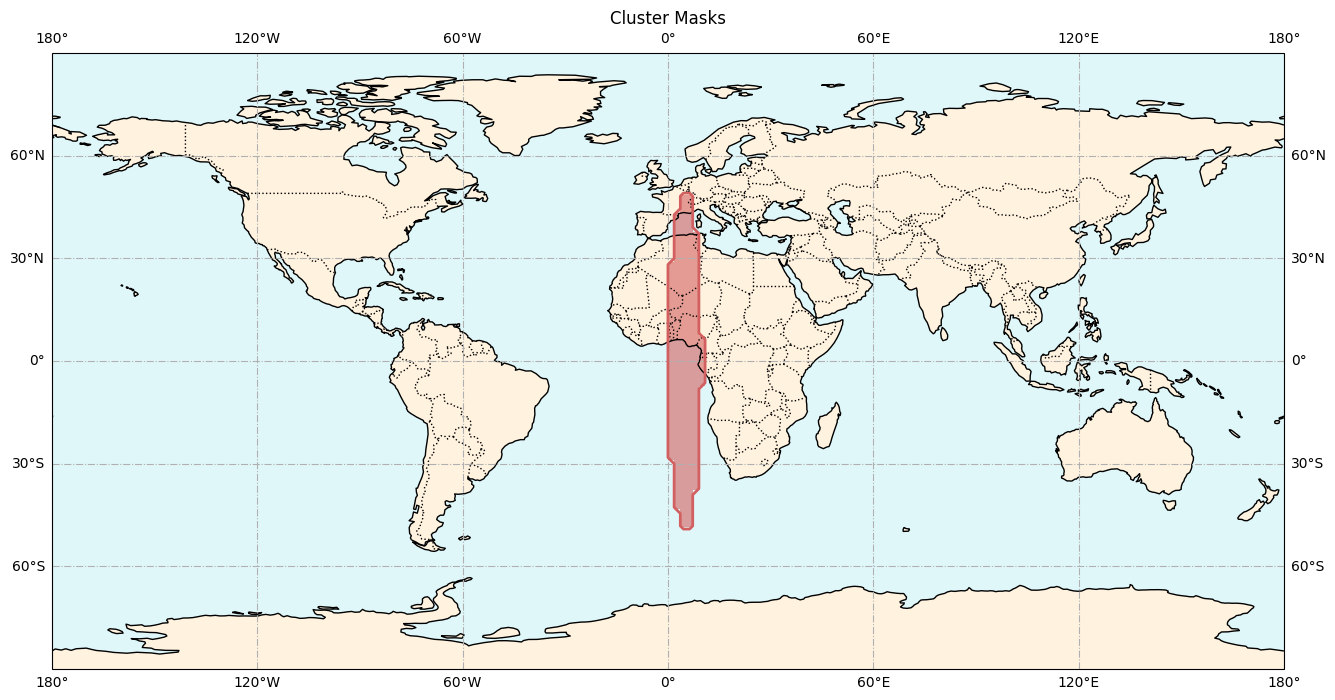

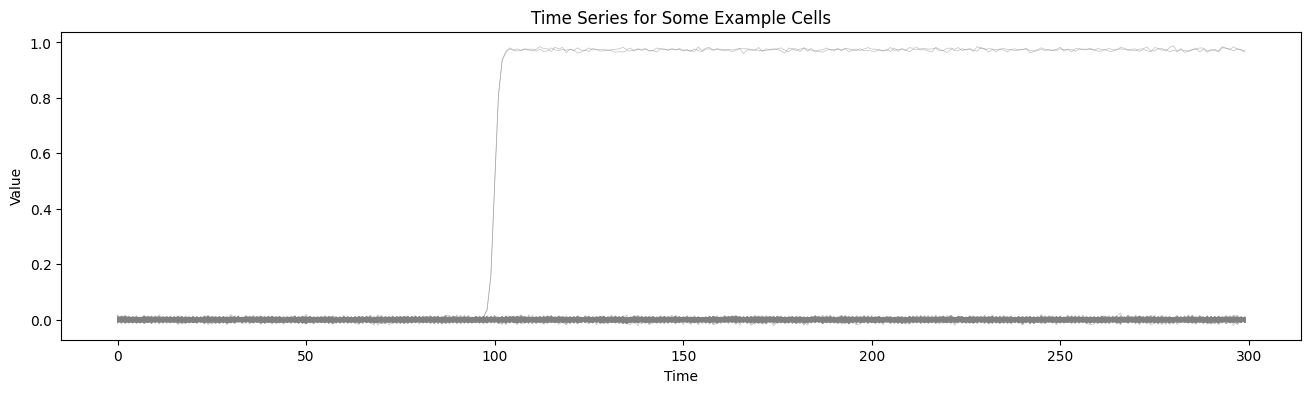

In [163]:
from ponds import PONDS, SIGMOID, ELLIPSIS, WhiteNoise

pd = PONDS(
    lat_size = 100,
    lon_size = 200,
    time_size = 300
)

pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.005,
        background_seed=42
    )
)

pd.add_shift(
    shift_method=SIGMOID(
        central_time=100,
        shift_seed = 3,
    ),
    shape_method=ELLIPSIS(
        center_lat=0,
        center_lon=5,
        ecc_lat=50,
        ecc_lon=5,
    )
)

#pd.add_shift(
#    shift_method=SIGMOID(
#        central_time=150,
#        shift_seed = 2,
#    ),
#    shape_method=ELLIPSIS(
#        center_lat=0,
#        center_lon=-5,
#        ecc_lat=50,
#        ecc_lon=5,
#    )
#)

fig, ax = pd.worldmap()
fig, ax = pd.plot_some_ts(
    ratio=0.01
)

In [126]:
pd.data

<xarray.Dataset> Size: 18MB
Dimensions:  (time: 100, lat: 100, lon: 200)
Coordinates:
  * time     (time) float64 800B 0.0 1.0 2.0 3.0 4.0 ... 96.0 97.0 98.0 99.0
  * lat      (lat) float64 800B -90.0 -88.18 -86.36 -84.55 ... 86.36 88.18 90.0
  * lon      (lon) float64 2kB -180.0 -178.2 -176.4 -174.6 ... 176.4 178.2 180.0
Data variables:
    ts       (time, lat, lon) float64 16MB 0.001524 -0.001891 ... 0.00305
    c1       (time, lat, lon) bool 2MB False False False ... False False False
Attributes:
    cluster_key:     c
    background_key:  b

In [127]:
# extract ground truth masks
GT_masks = {}
for i in range(len(pd.data)-1):
    GT_masks[i] = pd.data[f"c{i+1}"].values
print(f"Number of clusters: {len(GT_masks)}")

Number of clusters: 1


In [168]:
from sklearn.cluster import HDBSCAN
from toad.shifts import ASDETECT
from toad import TOAD
import numpy as np

#td = TOAD("../toad/tutorials/test_data/global_mean_summer_tas.nc") # data is in TOADtorial repo
# td.data = td.data.coarsen(lat=3, lon=3, boundary='trim').mean() # un-comment to speed up
td = TOAD(pd.data)
#display(td)

td.compute_shifts("ts",
    method=ASDETECT(
        ignore_nan_warnings=True,
        ))

td.compute_clusters("ts",
    shift_threshold=0.7,
    method=HDBSCAN(
        min_cluster_size=25
        #min_samples=5,  # optional, defaults to min_cluster_size
        #cluster_selection_epsilon=0.5,  # optional, defauls to 0
        #metric="euclidean",  # optional, defaults to 'euclidean'
    ), 
    overwrite=True
)

display(td)

INFO: New shifts variable ts_dts: min/mean/max=-0.875/0.002/0.902 using 20000 grid cells. Skipped 0.0% grid cells: 0 NaN, 0 constant.
INFO: New cluster variable ts_dts_cluster: Identified 0 clusters in 267 pts; Left 100.0% as noise (267 pts).


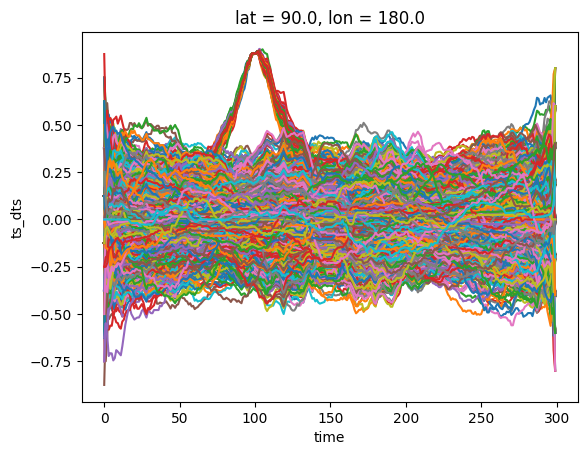

In [165]:
for i in range(0,td.data.ts_dts.shape[1]):
    for j in range(0,td.data.ts_dts.shape[2]):
        td.data.ts_dts[:,i,j].plot()
#td.data.ts_dts[:,0,0].plot()

In [167]:
td.plot.cluster_overview(
    "ts",
    cluster_ids=range(5),  # plot the 5 largest clusters
    #projection="south_pole",
)



ValueError: ('No clusters found for variable', 'ts')

In [107]:
# extract detection masks
# - split the data into 3D masks per cluster
cluster_arr = td.data.ts_dts_cluster.values
cluster_ids = np.unique(cluster_arr)
cluster_ids = cluster_ids[cluster_ids != -1]  # exclude non-clustered points
D_masks = {}
for cid in cluster_ids:
    D_masks[cid] = (cluster_arr == cid)

print(f"Number of clusters: {len(D_masks)}")

Number of clusters: 12


In [136]:
# fragmentation example
i = 0
OS = overlap_score(GT_masks, D_masks, temporal_uncertainty=3)
print("Overlap score matrix:")
print(OS)

FS = F_score(np.sum(GT_masks[i]), OS[i])
print(f"F-score of GT-cluster-{i}:", FS)

Overlap score matrix:
[[180.  32.   7.   5.]
 [  0.   0.   0.   0.]]
F-score of GT-cluster-0: 0.64103196255354


In [139]:
# unification example
i = 0
OS = overlap_score(D_masks, GT_masks, temporal_uncertainty=3)
print("Overlap score matrix:")
print(OS)

US = F_score(np.sum(D_masks[i]), OS[:,i])
print(f"U-score of D-cluster-{i}:", US)

Overlap score matrix:
[[180.   0.]
 [ 32.   0.]
 [  7.   0.]
 [  5.   0.]]
U-score of D-cluster-0: 0.08794554280045352
